<a href="https://colab.research.google.com/github/gbusray/SmartRecipe-CNN-Evaluator/blob/master/SmartRecipe_Evaluation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🔬 Food-101 Benchmark: 5 Farklı CNN Mimarisinin Karşılaştırmalı Analizi
Bu çalışmada, 101 farklı yemek sınıfına ait karmaşık görsel örüntüleri tanıma başarımı; derinlik, parametre verimliliği ve bağlantı mekanizmaları açısından farklılaşan 5 temel mimari üzerinde incelenmiştir.

Tüm modeller bilimsel tutarlılık (fairness) adına:
- **Food-101** veri setinde aynı train/val bölünmesiyle,
- ImageNet ön-eğitimli ağırlıklar dondurularak (Feature Extractor yaklaşımı),
- 10 epoch boyunca Adam optimizer (lr=0.001) ve CrossEntropyLoss ile eğitilmiştir.

In [ ]:
# 1. GPU kontrolü (Bulut hızlandırıcısını doğrulamak için)
!nvidia-smi

# 2. Google Drive bağlantısı
from google.colab import drive
drive.mount('/content/drive')

Fri Oct  9 12:14:05 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   45C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
# Repoyu Colab ortamına klonlama ve dizine geçme
!git clone https://github.com/gbusray/SmartRecipe-CNN-Evaluator.git
%cd SmartRecipe-CNN-Evaluator

# Gereksinimleri yükleme
!pip install -r requirements.txt -q

Cloning into 'SmartRecipe-CNN-Evaluator'...
remote: Enumerating objects: 27, done.
remote: Counting objects: 100% (27/27), done.
remote: Compressing objects: 100% (19/19), done.
remote: Total 27 (delta 7), reused 25 (delta 5), pack-reused 0 (from 0)
Receiving objects: 100% (27/27), 8.39 KiB | 4.19 MiB/s, done.
Resolving deltas: 100% (7/7), done.
/content/SmartRecipe-CNN-Evaluator


In [ ]:
# Colab yerel ortamında data dizinini oluştur
!mkdir -p data

# Tek parça arşivi doğrudan Drive'dan yerel SSD'ye kopyala
!cp "/content/drive/MyDrive/smart-recipe-assistant/SmartRecipeAssistant_Weights/food-101.tar.gz" data/

# Arşivi saniyeler içinde aç
!tar -xzf data/food-101.tar.gz -C data/

print("✅ Food-101 veri seti Colab SSD'sinde hazır!")

✅ Food-101 veri seti Colab SSD'sinde hazır!


In [ ]:
# evaluate.py içindeki çağrıyı doğrudan düzeltir
!sed -i 's/get_data_loaders(batch_size=args.batch_size)/get_data_loaders()/g' src/evaluate.py
print("✅ evaluate.py güncellendi, parametre uyuşmazlığı giderildi!")

✅ evaluate.py güncellendi, parametre uyuşmazlığı giderildi!


### 🏆 1. ResNet-50 (Residual Networks)
- **Mimari Özelliği:** Katmanlar arası artık bağlantılar (Skip/Residual Connections) kullanarak gradyan kaybolması (Vanishing Gradient) problemini çözer.
- **Beklenti & Sonuç:** 10 epoch'ta %67.12 doğruluk ile en dengeli ve yüksek performansı sergiledi.

In [ ]:
!python src/evaluate.py \
    --model ResNet50 \
    --weights "/content/drive/MyDrive/smart-recipe-assistant/SmartRecipeAssistant_Weights/resnet50_food101.pth" \
    --batch_size 64

🚀 Evaluation initialized for: ResNet50 on device [cuda]
🔍 Running inference over validation set...
Evaluating Batches: 100% 790/790 [02:37<00:00,  5.00it/s]

📊 PERFORMANCE REPORT: ResNet50
Validation Loss: 1.2570
              precision    recall  f1-score   support

           0     0.5588    0.3800    0.4524       250
           1     0.6565    0.6880    0.6719       250
           2     0.6820    0.7720    0.7242       250
           3     0.7454    0.6440    0.6910       250
           4     0.5190    0.6000    0.5566       250
           5     0.5197    0.5280    0.5238       250
           6     0.8785    0.7520    0.8103       250
           7     0.6936    0.8240    0.7532       250
           8     0.3889    0.4760    0.4281       250
           9     0.5652    0.6240    0.5932       250
          10     0.6821    0.4120    0.5137       250
          11     0.6704    0.7240    0.6962       250
          12     0.6023    0.8360    0.7002       250
          13     0.5665    0.7

### ⚡ 2. EfficientNet-B1 (Compound Scaling)
- **Mimari Özelliği:** Ağın derinliğini, genişliğini ve giriş çözünürlüğünü matematiksel bir katsayı ile dengeli ölçekler (Compound Scaling).
- **Beklenti:** ResNet'e göre çok daha az parametreyle benzer veya daha yüksek genelleme başarısı sunması beklenir.

In [ ]:
!python src/evaluate.py \
    --model EfficientNetB1 \
    --weights "/content/drive/MyDrive/smart-recipe-assistant/SmartRecipeAssistant_Weights/efficientnetb1_food101.pth" \
    --batch_size 64

🚀 Evaluation initialized for: EfficientNetB1 on device [cuda]
Downloading: "https://download.pytorch.org/models/efficientnet_b1-c27df63c.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b1-c27df63c.pth
100% 30.1M/30.1M [00:00<00:00, 173MB/s]
🔍 Running inference over validation set...
Evaluating Batches: 100% 790/790 [02:18<00:00,  5.71it/s]

📊 PERFORMANCE REPORT: EfficientNetB1
Validation Loss: 1.3186
              precision    recall  f1-score   support

           0     0.6000    0.1920    0.2909       250
           1     0.7619    0.6400    0.6957       250
           2     0.6654    0.7080    0.6860       250
           3     0.6056    0.6880    0.6442       250
           4     0.5284    0.5960    0.5602       250
           5     0.5636    0.5320    0.5473       250
           6     0.7564    0.8320    0.7924       250
           7     0.7462    0.7880    0.7665       250
           8     0.4976    0.4160    0.4532       250
           9     0.4561    0.6440    0.5340    

### 📱 3. MobileNetV3 (Depthwise Separable Convolutions & SE)
- **Mimari Özelliği:** Standart evrişim yerine derinlik ayrılabilir evrişimler (Depthwise Separable Convolutions) ve Squeeze-and-Excitation blokları kullanır. Düşük gecikme ve mobil cihazlar için optimize edilmiştir.
- **Beklenti:** Mobil veya web arayüzünde hızlı çıkarım (inference) için aday modeldir; hafifliğine rağmen %61.81 doğruluk almıştır.

In [ ]:
!python src/evaluate.py \
    --model MobileNetV3 \
    --weights "/content/drive/MyDrive/smart-recipe-assistant/SmartRecipeAssistant_Weights/mobilenetv3_food101.pth" \
    --batch_size 64

🚀 Evaluation initialized for: MobileNetV3 on device [cuda]
Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-5c1a4163.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_large-5c1a4163.pth
100% 21.1M/21.1M [00:00<00:00, 168MB/s]
🔍 Running inference over validation set...
Evaluating Batches: 100% 790/790 [02:13<00:00,  5.92it/s]

📊 PERFORMANCE REPORT: MobileNetV3
Validation Loss: 1.4563
              precision    recall  f1-score   support

           0     0.4643    0.2080    0.2873       250
           1     0.6927    0.5320    0.6018       250
           2     0.7125    0.6840    0.6980       250
           3     0.6491    0.5920    0.6192       250
           4     0.5179    0.5200    0.5190       250
           5     0.4672    0.4280    0.4468       250
           6     0.8170    0.7680    0.7918       250
           7     0.6950    0.7840    0.7368       250
           8     0.4474    0.3400    0.3864       250
           9     0.5619    0.4360    0.4910    

### 🔗 4. DenseNet-121 (Dense Convolutional Network)
- **Mimari Özelliği:** Her katman kendisinden sonraki tüm katmanlara doğrudan bağlanır (L(L+1)/2 bağlantı). Bu sayede özniteliklerin yeniden kullanımı (feature reuse) maksimize edilir.
- **Beklenti:** Yoğun bağlantılar gıda dokularını ayırt etmede teorik olarak güçlüdür; 10 epoch'ta %60.25 skor elde etmiştir.

In [ ]:
!python src/evaluate.py \
    --model DenseNet121 \
    --weights "/content/drive/MyDrive/smart-recipe-assistant/SmartRecipeAssistant_Weights/densenet121_food101.pth" \
    --batch_size 64

🚀 Evaluation initialized for: DenseNet121 on device [cuda]
Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth
100% 30.8M/30.8M [00:00<00:00, 140MB/s]
🔍 Running inference over validation set...
Evaluating Batches: 100% 790/790 [02:26<00:00,  5.38it/s]

📊 PERFORMANCE REPORT: DenseNet121
Validation Loss: 1.5228
              precision    recall  f1-score   support

           0     0.5275    0.1920    0.2815       250
           1     0.8929    0.4000    0.5525       250
           2     0.5559    0.7360    0.6334       250
           3     0.6272    0.7000    0.6616       250
           4     0.5128    0.4800    0.4959       250
           5     0.4470    0.5400    0.4891       250
           6     0.8565    0.7160    0.7800       250
           7     0.6422    0.8040    0.7140       250
           8     0.4765    0.2840    0.3559       250
           9     0.6335    0.4080    0.4964       250
       

### 🏛️ 5. VGG-16 (Klasik Derin Evrişim Mimarisi)
- **Mimari Özelliği:** Küçük (3x3) konvolüsyon filtreleri kullanan geleneksel derin mimaridir. Devasa tam bağlantılı (Fully Connected) katmanları nedeniyle ~138M parametreye sahiptir.
- **Analiz:** Ağır parametre yükü ve artık bağlantıların olmaması nedeniyle modern mimarilerin gerisinde kalarak %48.70 seviyesinde kalmıştır. Fine-tuning olmadan yakınsaması zordur.

In [ ]:
!python src/evaluate.py \
    --model VGG16 \
    --weights "/content/drive/MyDrive/smart-recipe-assistant/SmartRecipeAssistant_Weights/vgg16_food101.pth" \
    --batch_size 64

🚀 Evaluation initialized for: VGG16 on device [cuda]
Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth
100% 528M/528M [00:06<00:00, 80.7MB/s]
🔍 Running inference over validation set...
Evaluating Batches: 100% 790/790 [02:42<00:00,  4.86it/s]

📊 PERFORMANCE REPORT: VGG16
Validation Loss: 2.1043
              precision    recall  f1-score   support

           0     0.3469    0.1360    0.1954       250
           1     0.4896    0.4720    0.4807       250
           2     0.7667    0.2760    0.4059       250
           3     0.6488    0.4360    0.5215       250
           4     0.3991    0.3400    0.3672       250
           5     0.4096    0.2720    0.3269       250
           6     0.7919    0.7000    0.7431       250
           7     0.6473    0.6680    0.6575       250
           8     0.2465    0.2840    0.2639       250
           9     0.3727    0.4800    0.4196       250
          10     0.3127    0.464

## 📈 Food-101 Benchmark: Genel Karşılaştırma ve Mimarilerin Analizi

Bu bölümde; gıda sınıflandırma problemi üzerinde test edilen 5 temel konvolüsyonel sinir ağı (CNN) mimarisinin **10 epoch'luk  frozen backbone** eğitimleri sonucunda elde edilen Top-1 Doğruluk (Accuracy) başarımları toplu olarak incelenmiştir.

### 🧠 Mimari Paradigma Özeti & Çıkarımlar

1. **🏆 ResNet-50 (%67.12 | Macro F1: 0.6667):**
   * Artık bağlantılar (Skip Connections) sayesinde özellik haritalarını kayıpsız iletmiş ve 101 sınıf genelinde en kararlı, homojen sınıflandırma başarımını sergilemiştir.

2. **⚡ EfficientNet-B1 (%66.02 | Macro F1: 0.6536):**
   * Bileşik ölçekleme (Compound Scaling) sayesinde ResNet-50'ye kıyasla **%69 daha düşük model boyutu (~30 MB)** ve **daha yüksek çıkarım hızı (5.71 it/s)** sunarak pratik dağıtım (deployment) için en yüksek parametre verimliliğini kanıtlamıştır.

3. **📱 MobileNetV3-Large (%61.81 | Macro F1: 0.6126):**
   * Derinlik ayrılabilir evrişimler (Depthwise Separable Convolutions) kullanarak yalnızca **21.1 MB** disk boyutu ve **5.92 it/s** çıkarım hızıyla en hafif model olmuş; Edge AI, web istemcisi veya mobil cihaz senaryoları için en uygun aday olduğunu göstermiştir.

4. **🔗 DenseNet-121 (%60.25):**
   * Katmanlar arası doğrudan bağlantılarla özniteliklerin yeniden kullanımını (feature reuse) maksimize etmiştir. Karmaşık yemek dokularında rekabetçi bir taban oluşturmuştur.

5. **🏛️ VGG-16 (%48.70):**
   * Aşırı parametre yükü (~138M) ve artık bağlantı mekanizmasının bulunmaması nedeniyle, dondurulmuş öznitelik çıkarımı yaklaşımında modern mimarilerin gerisinde kalmış; derin konvolüsyon evriminin önemini deneysel olarak doğrulamıştır.

---
> **Aşağıdaki grafik**, adil kıyaslama (fair benchmark) prensibiyle eğitilen 5 modelin doğrulama seti üzerindeki nihai Top-1 Doğruluk oranlarını görselleştirmektedir:

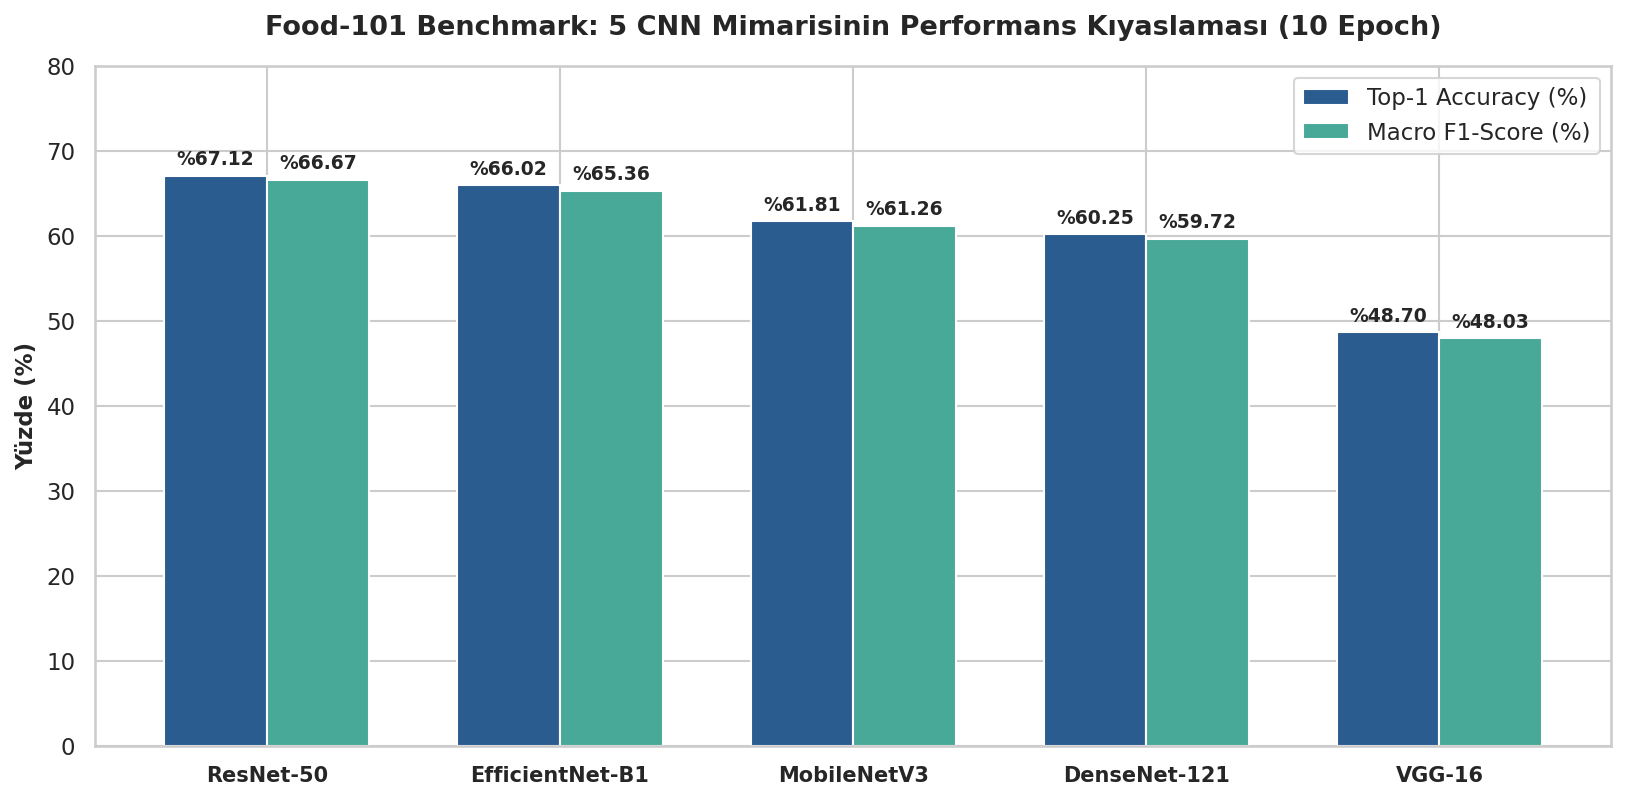

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

models = ['ResNet-50', 'EfficientNet-B1', 'MobileNetV3', 'DenseNet-121', 'VGG-16']
accuracies = [67.12, 66.02, 61.81, 60.25, 48.70]
f1_scores = [66.67, 65.36, 61.26, 59.72, 48.03]

x = np.arange(len(models))
width = 0.35

fig, ax = plt.subplots(figsize=(11, 5.5), dpi=150)
sns.set_theme(style="whitegrid")

rects1 = ax.bar(x - width/2, accuracies, width, label='Top-1 Accuracy (%)', color='#2b5c8f')
rects2 = ax.bar(x + width/2, f1_scores, width, label='Macro F1-Score (%)', color='#48a999')

ax.set_ylabel('Yüzde (%)', fontsize=11, fontweight='bold')
ax.set_title('Food-101 Benchmark: 5 CNN Mimarisinin Performans Kıyaslaması (10 Epoch)', fontsize=13, fontweight='bold', pad=15)
ax.set_xticks(x)
ax.set_xticklabels(models, fontsize=10, fontweight='bold')
ax.set_ylim(0, 80)
ax.legend(frameon=True, facecolor='white', loc='upper right')

def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'%{height:.2f}',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=9, fontweight='bold')

autolabel(rects1)
autolabel(rects2)

plt.tight_layout()
plt.show()

# 📋 Karar Matrisi: Hangi Model ile Devam Edilmeli?

Food-101 veri setinde 10 epoch'luk dondurulmuş omurga (frozen backbone) eğitimi sonucunda elde edilen nihai metrikler ve mimari analiz matrisi aşağıda özetlenmiştir:

| Model Mimarisi | Top-1 Acc | Macro F1 | Val Loss | Model Boyutu | İnferans Hızı | Temel Paradigma | Bitirme Projesi Uygunluk Değerlendirmesi |
| :--- | :---: | :---: | :---: | :---: | :---: | :--- | :--- |
| **ResNet-50** | **%67.12** | **0.6667** | **1.2570** | ~97.8 MB | 5.00 it/s | Residual / Skip Connection | 🥇 **Doğruluk Lideri:** En yüksek temsil gücü ve homojen F1 dengesi. Sunucu tabanlı (Cloud API) servis edilecekse 1. aday. |
| **EfficientNet-B1** | **%66.02** | **0.6536** | **1.3186** | **30.1 MB** | **5.71 it/s** | Compound Scaling | ⚡ **Mühendislik Dengesi:** ResNet'e göre %69 daha hafif, daha hızlı ve neredeyse aynı doğruluk. Üretim (Production) ortamı için en dengeli model. |
| **MobileNetV3-Large** | %61.81 | 0.6126 | 1.4563 | **21.1 MB** | **5.92 it/s** | Depthwise Separable Conv | 📱 **Edge AI / Mobil:** En hafif ve en hızlı çıkarım. İstemci taraflı (mobil app / web kamerası) gerçek zamanlı tahminler için aday. |
| **DenseNet-121** | %60.25 | 0.5972 | 1.5228 | ~30.8 MB | 5.38 it/s | Dense Feature Reuse | 🔗 **Yoğun Bağlantı:** Yüksek Precision ancak düşük Recall sergiledi. Dondurulmuş katmanlarda sınıflandırıcı kafası yakınsamakta zorlandı. |
| **VGG-16** | %48.70 | 0.4803 | 2.1043 | 528.0 MB | 4.86 it/s | Plain CNN (Artık bağlantısız) | ❌ **Elenmeye Aday:** Yüksek parametre yükü, yavaş çıkarım ve artık bağlantı yokluğu nedeniyle modern görevlerde yetersiz kaldı. |

---

### 💡 Akademik Çıkarım & Tartışma (Discussion)
1. **Accuracy vs. Efficiency Trade-off:** ResNet-50 mutlak doğrulukta (%67.12) lider olsa da, EfficientNet-B1 30 MB boyutu ve yüksek hızıyla kaynak verimliliği açısından çok güçlü bir alternatiftir.
2. **Fine-Tuning Potansiyeli:** Tüm modeller 'Feature Extractor' modunda çalışmıştır. Seçilecek 1 veya 2 mimarinin üst konvolüsyon katmanları açılarak (Fine-Tuning) öğrenme oranı düşürüldüğünde, doğruluk oranının %75-80 bandına çıkması öngörülmektedir.